In [53]:
from sklearn import datasets, model_selection, svm, metrics, multiclass, inspection
import numpy as np
import matplotlib.pyplot as plt

In [54]:
iris = datasets.load_iris()

In [55]:
# Split into train/test
X = iris.data
Y = iris.target

X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X, Y, test_size=0.2, random_state=69, stratify=Y)

print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

(120, 4) (30, 4) (120,) (30,)


In [56]:
def create_model(kernel):
    model = svm.SVC(kernel=kernel)
    return model

In [57]:
def train_model(model, X, Y):
    model.fit(X,Y)

In [58]:
def test_model(model, X_test):
    return model.predict(X_test)

In [59]:
kernels = ["linear", "poly", "rbf"]
approaches = [multiclass.OneVsOneClassifier, multiclass.OneVsRestClassifier]
results = {}

for kernel in kernels:
    for i, approach in enumerate(approaches):
        model = approach(create_model(kernel))
        train_model(model, X_train, Y_train)
        Y_pred = test_model(model, X_test)
        acc = metrics.accuracy_score(Y_test, Y_pred)
        f1 = metrics.f1_score(Y_test, Y_pred, average="macro")
        cm = metrics.confusion_matrix(Y_test, Y_pred)

        results[(kernel, i)] = {
            "model": model,
            "kernel": kernel,
            "approach": i,
            "acc": acc,
            "f1": f1,
            "cm": cm
        }

        print(f"Kernel: {kernel}_{i}\n\tAcc: {acc}\n\tF1: {f1}\n{cm}\n\n")

best = max(results, key=lambda k: (results[k]["acc"], results[k]["f1"]))
print("Best:", best)

Kernel: linear_0
	Acc: 1.0
	F1: 1.0
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


Kernel: linear_1
	Acc: 0.9333333333333333
	F1: 0.9333333333333332
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


Kernel: poly_0
	Acc: 1.0
	F1: 1.0
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


Kernel: poly_1
	Acc: 1.0
	F1: 1.0
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


Kernel: rbf_0
	Acc: 0.9
	F1: 0.899749373433584
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


Kernel: rbf_1
	Acc: 0.8666666666666667
	F1: 0.8653198653198654
[[10  0  0]
 [ 0  9  1]
 [ 0  3  7]]


Best: ('linear', 0)


In [60]:
model = results[("linear", 1)]["model"]

for i, estimator in enumerate(model.estimators_):
    print(f"Class {i} support vectors ({len(estimator.support_vectors_)}): {estimator.support_vectors_}")

Class 0 support vectors (3): [[5.1 2.5 3.  1.1]
 [5.1 3.3 1.7 0.5]
 [4.5 2.3 1.3 0.3]]
Class 1 support vectors (73): [[6.  3.  4.8 1.8]
 [4.9 3.  1.4 0.2]
 [6.4 2.8 5.6 2.2]
 [7.7 2.8 6.7 2. ]
 [6.5 3.  5.5 1.8]
 [4.8 3.  1.4 0.1]
 [6.3 2.8 5.1 1.5]
 [6.5 3.  5.8 2.2]
 [4.3 3.  1.1 0.1]
 [5.9 3.  5.1 1.8]
 [7.2 3.  5.8 1.6]
 [6.1 2.6 5.6 1.4]
 [4.5 2.3 1.3 0.3]
 [6.3 3.3 6.  2.5]
 [4.8 3.1 1.6 0.2]
 [4.8 3.  1.4 0.3]
 [6.5 3.  5.2 2. ]
 [6.7 2.5 5.8 1.8]
 [4.4 2.9 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [5.6 2.8 4.9 2. ]
 [5.8 2.7 5.1 1.9]
 [6.2 2.8 4.8 1.8]
 [5.  3.  1.6 0.2]
 [4.9 3.1 1.5 0.2]
 [6.4 2.8 5.6 2.1]
 [4.6 3.1 1.5 0.2]
 [6.4 2.7 5.3 1.9]
 [7.4 2.8 6.1 1.9]
 [7.7 2.6 6.9 2.3]
 [6.3 2.9 5.6 1.8]
 [4.9 2.5 4.5 1.7]
 [6.3 2.5 5.  1.9]
 [6.4 3.1 5.5 1.8]
 [7.7 3.  6.1 2.3]
 [7.6 3.  6.6 2.1]
 [7.3 2.9 6.3 1.8]
 [4.9 2.4 3.3 1. ]
 [5.1 2.5 3.  1.1]
 [6.7 3.1 4.7 1.5]
 [5.6 2.7 4.2 1.3]
 [6.2 2.2 4.5 1.5]
 [6.4 3.2 4.5 1.5]
 [6.8 2.8 4.8 1.4]
 [5.5 2.4 3.8 1.1]
 [5.8 2.7 4.1 1. ]
 [6.  2.7

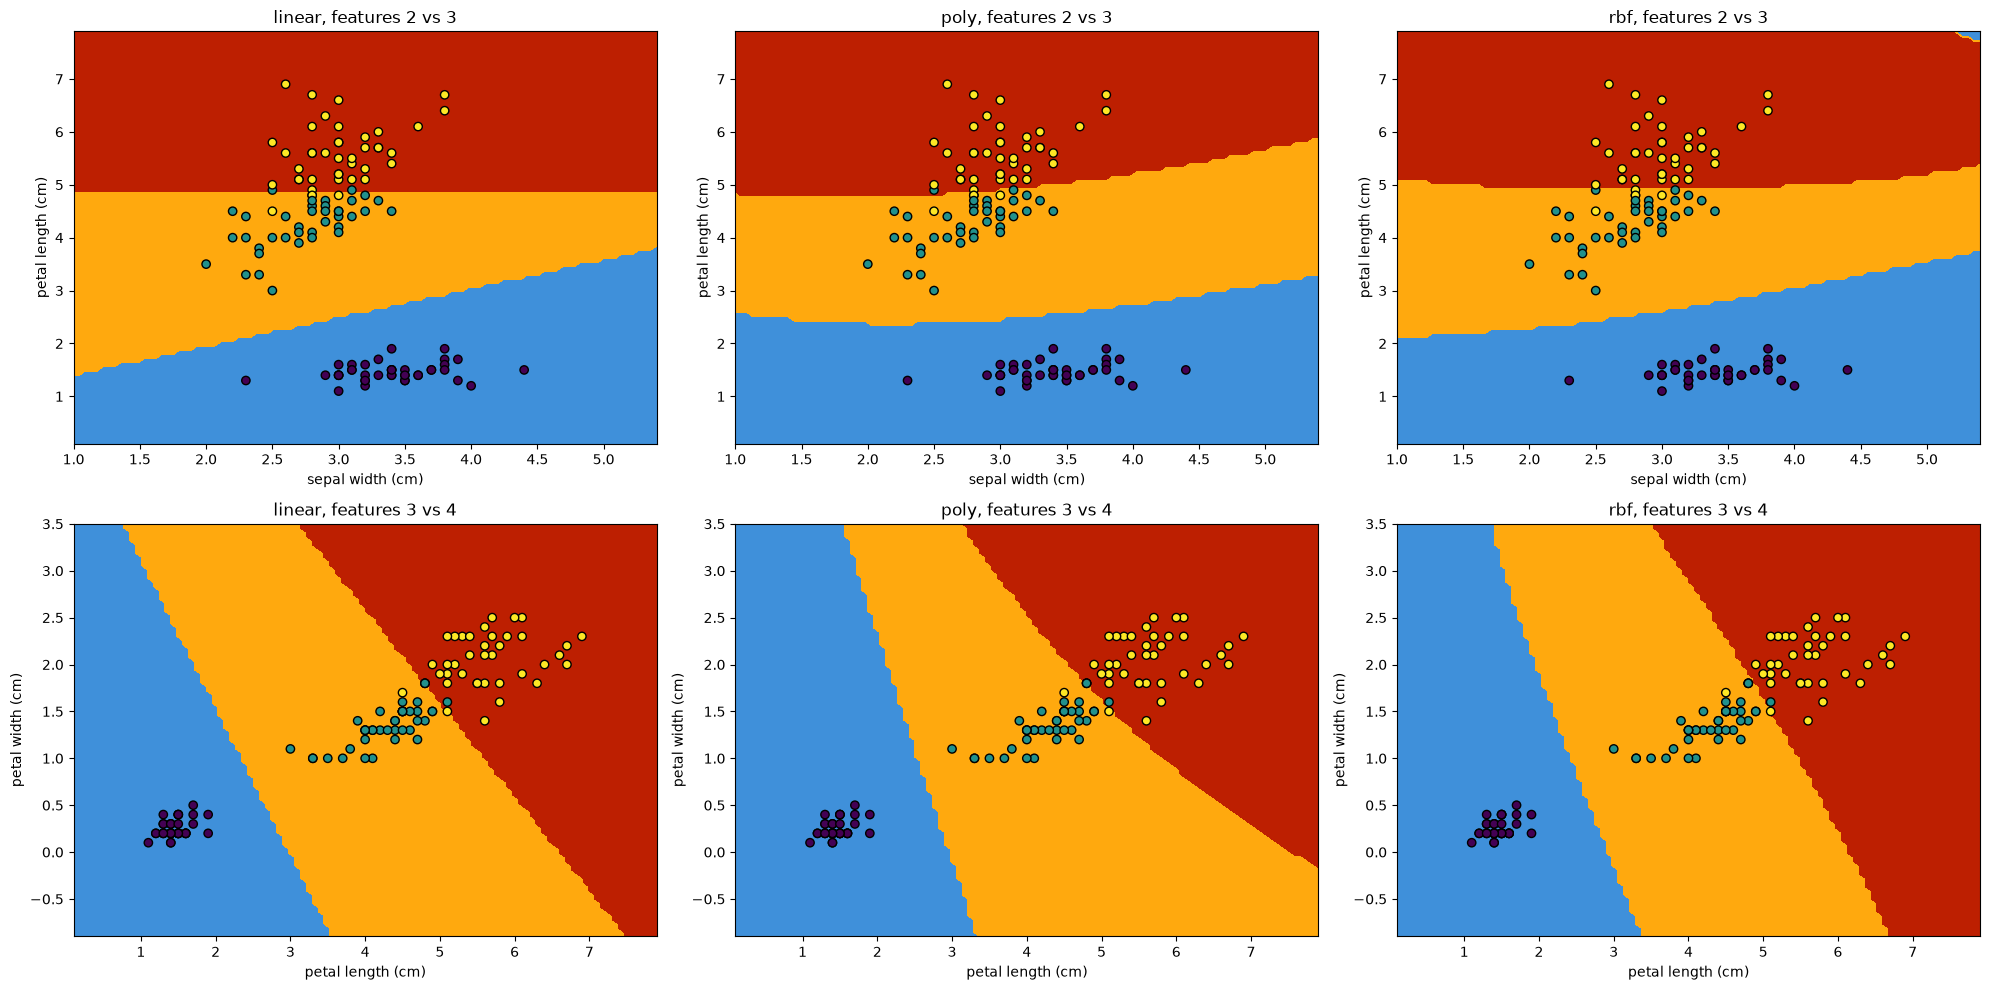

In [ ]:
features_indices = [(1,2), (2,3)]

fig, axes = plt.subplots(len(features_indices), len(kernels), figsize=(20,10))
for i, (a, b) in enumerate(features_indices):
    X_train_subset = X_train[:, [a,b]]


    for j, kernel in enumerate(kernels):
        model = create_model(kernel)
        train_model(model, X_train_subset, Y_train)
        ax = axes[i,j]

        inspection.DecisionBoundaryDisplay.from_estimator(model, X_train_subset, ax=ax, response_method="predict")

        ax.scatter(X_train[:, a], X_train[:, b], c=Y_train, edgecolor="k")
        ax.set_xlabel(iris.feature_names[a])
        ax.set_ylabel(iris.feature_names[b])
        ax.set_title(f"{kernel}, features {a+1} vs {b+1}")
plt.tight_layout()
plt.show()